# Guía Aplicativa — Grupo 02: Estimación de Carga Térmica de Edificios con MLP
**Asignatura:** Sistemas Inteligentes y Machine Learning  
**Dataset:** UCI Machine Learning Repository — *Energy Efficiency* (ID 242, `ENB2012_data.xlsx`)  
**Semilla global reproducible:** `SEED = 42`

Este cuaderno desarrolla de forma ordenada y verificable las **16 etapas obligatorias** de la guía académica, manteniendo el conjunto **Test completamente aislado** hasta la evaluación final.

In [1]:
import sys
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Garantizar importación de los módulos locales del repositorio
ROOT_DIR = Path("..").resolve()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.data_loader import (
    FEATURE_COLS, CONTINUOUS_COLS, CATEGORICAL_COLS, TARGET_COL,
    X6_LABELS, X8_LABELS, load_dataset, get_variable_summary_df
)
from src.modeling import (
    SEED, split_dataset, build_preprocessor, count_mlp_parameters,
    run_all_experiments, check_domain_and_geometry
)

plt.rcParams["figure.dpi"] = 110
sns.set_style("whitegrid")
np.random.seed(SEED)
print(f"Entorno inicializado desde: {ROOT_DIR} | SEED = {SEED}")

/home/gerardo/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-2f18nhqd because there was an issue with the default path (/home/gerardo/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Entorno inicializado desde: /home/gerardo/dev/python/SI-S12 | SEED = 42


## Etapa 01. Definición del problema
Una consultora de eficiencia energética necesita estimar de forma rápida la **carga de calefacción** (`Y1`) de un edificio a partir de sus características arquitectónicas y de envolvente térmica en etapas tempranas de diseño, evitando ejecutar simulaciones físicas completas para cada variante.

**Aclaración fundamental sobre el origen de los datos:** Las 768 observaciones no provienen de medidores reales instalados en viviendas habitadas, sino de simulaciones físicas en el software *Autodesk Ecotect* (Tsanas & Xifara, 2012) bajo supuestos controlados de clima, ocupación y materiales.

## Etapa 02. Tipo de aprendizaje
El problema se formula como **regresión supervisada tabular**:

$$\hat{Y}_1 = f_{\theta}(X_1, X_2, \dots, X_8) \in \mathbb{R}_{>0} \quad [\text{kWh/m}^2]$$

donde cada observación posee 8 características de diseño conocidas y una etiqueta continua objetivo (`Y1`, demanda anual de calefacción por unidad de área). El aprendizaje se evalúa mediante **MAE**, **RMSE** (métrica principal de selección en Validación) y **$R^2$**.

## Etapa 03. Obtención y trazabilidad de datos
Cargamos el dataset oficial `data/ENB2012_data.xlsx` / `data/energy_efficiency.csv` almacenado localmente en el repositorio para garantizar reproducibilidad sin depender de conexión externa.

In [2]:
df, metadata = load_dataset(prefer_local=True)
print(f"Archivo local Excel: {metadata['local_files']['xlsx']}")
print(f"Archivo local CSV:   {metadata['local_files']['csv']}")
print(f"Dimensiones:         {df.shape[0]} filas × {df.shape[1]} columnas")
print(f"Valores nulos totales: {int(df.isna().sum().sum())}")
print(f"Filas duplicadas:      {int(df.duplicated().sum())}")
display(df.head())

Archivo local Excel: data/ENB2012_data.xlsx
Archivo local CSV:   data/energy_efficiency.csv
Dimensiones:         768 filas × 10 columnas
Valores nulos totales: 0
Filas duplicadas:      0


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


## Etapa 04. Entradas, salidas y objetivo
Definimos explícitamente $X = [X_1, X_2, \dots, X_8]$ y $y = Y_1$.  
**Exclusión estricta de `Y2`:** La carga de refrigeración (`Y2`) es otra variable respuesta simultánea del simulador, no un dato de diseño previo. Incluir `Y2` como predictor provocaría **fuga de datos (*data leakage*)**.

In [3]:
X = df[FEATURE_COLS].copy()
y = df[TARGET_COL].copy()

print("Variables de entrada X:", list(X.columns))
print("Variable objetivo y:   ", y.name, "(kWh/m²)")
print("Excluida de X:          Y2 (Carga de refrigeración)")
print(f"Correlación Pearson(Y1, Y2) en todo el dataset: {df['Y1'].corr(df['Y2']):.4f}")
display(get_variable_summary_df(df))

Variables de entrada X: ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8']
Variable objetivo y:    Y1 (kWh/m²)
Excluida de X:          Y2 (Carga de refrigeración)
Correlación Pearson(Y1, Y2) en todo el dataset: 0.9759


,Variable,Nombre,Rol,Tipo,Unidad,Mín,Mediana,Media,Máx,Desv. Est.,Únicos,Nulos
0,X1,Compacidad relativa,Entrada (Continua),Continua,Adimensional (ratio),0.62,0.75,0.7642,0.98,0.1058,12,0
1,X2,Área superficial,Entrada (Continua),Continua,m²,514.50,673.75,671.7083,808.50,88.0861,12,0
2,X3,Área de paredes,Entrada (Continua),Continua,m²,245.00,318.50,318.5000,416.50,43.6265,7,0
3,X4,Área de techo,Entrada (Continua),Continua,m²,110.25,183.75,176.6042,220.50,45.1660,4,0
4,X5,Altura total,Entrada (Continua),Continua,m,3.50,5.25,5.2500,7.00,1.7511,2,0
5,X6,Orientación,Entrada (Categórica nominal),Nominal (codificada 2–5),Código nominal,2.00,3.50,3.5000,5.00,1.1188,4,0
6,X7,Área acristalada,Entrada (Continua),Continua,Proporción del piso (0.00–0.40),0.00,0.25,0.2344,0.40,0.1332,4,0
7,X8,Distribución del acristalamiento,Entrada (Categórica nominal),Nominal (codificada 0–5),Código nominal,0.00,3.00,2.8125,5.00,1.5510,6,0
8,Y1,Carga de calefacción (Heating Load),Objetivo principal (y),Continua,kWh/m²,6.01,18.95,22.3072,43.10,10.0902,587,0
9,Y2,Carga de refrigeración (Cooling Load),Objetivo secundario (excluida de X),Continua,kWh/m²,10.90,22.08,24.5878,48.03,9.5133,636,0


## Etapa 05. Análisis exploratorio (EDA)
Visualizamos la distribución de `Y1`, el mapa de correlaciones y la relación de `Y1` con **compacidad (`X1`)**, **altura (`X5`)**, **orientación (`X6`)** y **área acristalada (`X7`)**.

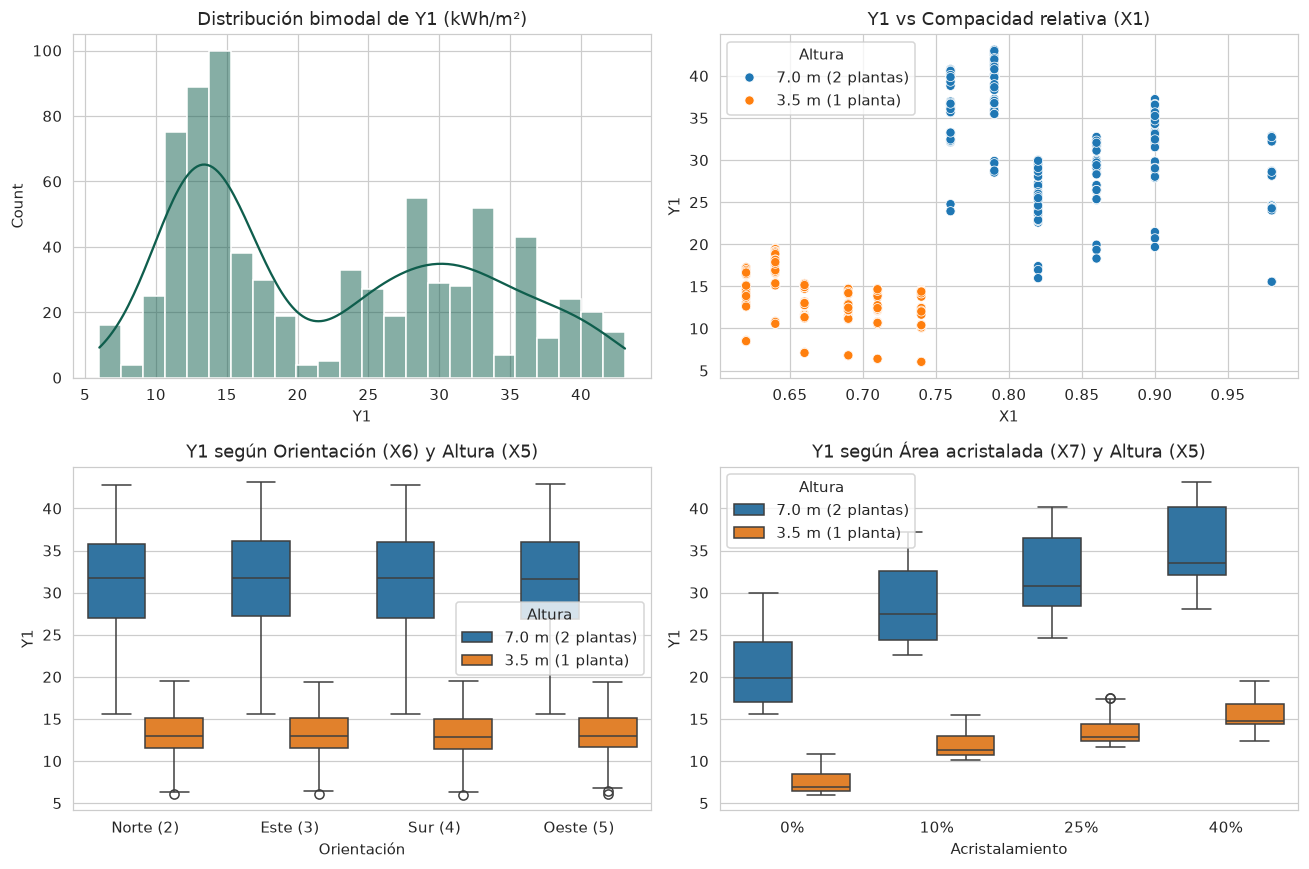

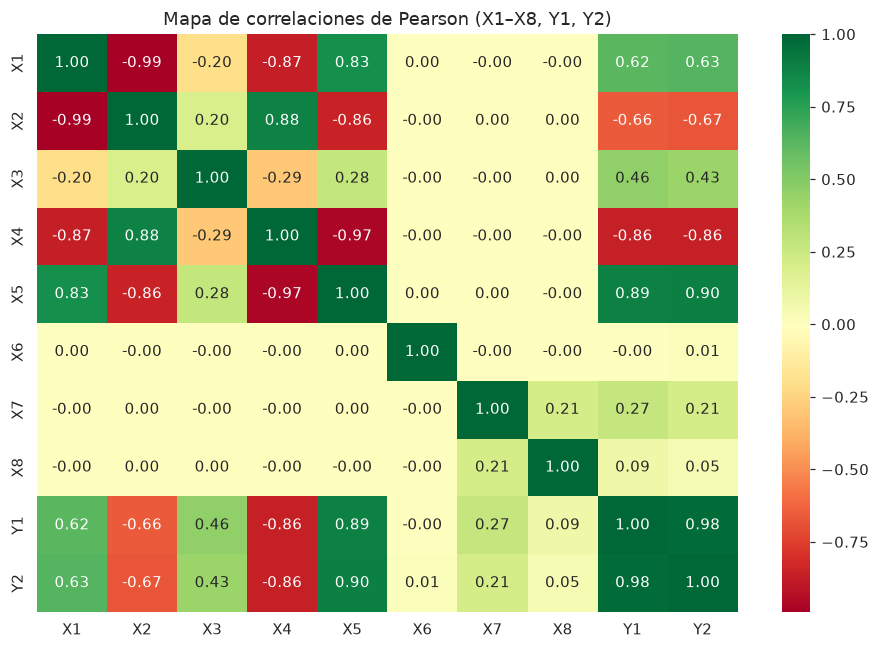

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
df_eda = df.copy()
df_eda["Altura"] = df_eda["X5"].map({3.5: "3.5 m (1 planta)", 7.0: "7.0 m (2 plantas)"})
df_eda["Orientación"] = df_eda["X6"].map(X6_LABELS)
df_eda["Acristalamiento"] = (df_eda["X7"] * 100).round(0).astype(int).astype(str) + "%"

sns.histplot(df_eda["Y1"], bins=24, kde=True, color="#0F5E4D", ax=axes[0, 0])
axes[0, 0].set_title("Distribución bimodal de Y1 (kWh/m²)")

sns.scatterplot(data=df_eda, x="X1", y="Y1", hue="Altura", ax=axes[0, 1])
axes[0, 1].set_title("Y1 vs Compacidad relativa (X1)")

sns.boxplot(data=df_eda, x="Orientación", y="Y1", hue="Altura", ax=axes[1, 0])
axes[1, 0].set_title("Y1 según Orientación (X6) y Altura (X5)")

sns.boxplot(data=df_eda, x="Acristalamiento", y="Y1", order=["0%", "10%", "25%", "40%"], hue="Altura", ax=axes[1, 1])
axes[1, 1].set_title("Y1 según Área acristalada (X7) y Altura (X5)")

plt.tight_layout()
plt.show()

plt.figure(figsize=(8.5, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="RdYlGn", center=0)
plt.title("Mapa de correlaciones de Pearson (X1–X8, Y1, Y2)")
plt.tight_layout()
plt.show()

## Etapa 06. Separación experimental
Dividimos el dataset en **Train (70%, 537)**, **Validation (15%, 115)** y **Test (15%, 116)** con estratificación conjunta por altura (`X5`) y área acristalada (`X7`) usando `SEED = 42`. Además conservamos el conjunto `Train+Val (652)` para validación cruzada 5-Fold.

**Nota de dependencia estructural:** El dataset surge de 12 geometrías base (`X1..X5`) replicadas en orientaciones y acristalamientos; verificamos que las 12 formas base quedan representadas de forma equilibrada y mantenemos **Test** completamente sellado durante todo el diseño.

In [5]:
split = split_dataset(df, seed=SEED)
train_df = split["train_df"]
val_df = split["val_df"]
test_df = split["test_df"]
print("Resumen de partición:", split["summary"])

Resumen de partición: {'seed': 42, 'total_rows': 768, 'train_rows': 537, 'val_rows': 115, 'test_rows': 116, 'train_val_rows': 652, 'stratified_by': 'X5 (altura) + X7 (área acristalada)', 'unique_base_geometries': {'total': 12, 'train': 12, 'val': 12, 'test': 12}}


## Etapa 07. Preprocesamiento
- **Variables continuas (`X1, X2, X3, X4, X5, X7`)**: `SimpleImputer(strategy="median")` + `StandardScaler()` (ajustado **solo** sobre Train dentro de `Pipeline`).
- **Variables categóricas nominales (`X6, X8`)**: `SimpleImputer(strategy="most_frequent")` + `OneHotEncoder()`, evitando imponer un orden artificial entre puntos cardinales.

In [6]:
pre_ohe = build_preprocessor(use_onehot=True)
X_tr_sample = pre_ohe.fit_transform(train_df[FEATURE_COLS])
print("Dimensión original de X:               ", train_df[FEATURE_COLS].shape[1], "columnas")
print("Dimensión transformada (con OneHot):   ", X_tr_sample.shape[1], "columnas (6 continuas + 4 de X6 + 6 de X8)")

Dimensión original de X:                8 columnas
Dimensión transformada (con OneHot):    16 columnas (6 continuas + 4 de X6 + 6 de X8)


## Etapas 08–15. Baselines, Diseño MLP, Experimentos A–D, Validación Cruzada y Evaluación Final
Ejecutamos nuestro protocolo experimental unificado (`run_all_experiments`), que comprende:
- **Etapa 08 (Baselines):** `DummyRegressor`, `Regresión Lineal` y `Random Forest (200 árboles)`.
- **Etapa 09 (Diseño de arquitectura MLP):** Entrada de 8 variables codificadas a 16 features, capas ocultas densas con activación **ReLU** ($a = \max(0, Wx + b)$) y **salida escalar lineal**.
- **Etapa 10 (Configuración de aprendizaje):** Pérdida cuadrática **MSE**, optimizador **Adam** (`learning_rate_init = 0.005`) y conteo exacto de parámetros entrenables.
- **Etapa 11 (Plan de hiperparámetros):** Experimentos **A** `(16)`, **B** `(32, 16)`, **C1** `(64, 32)` baja regularización, **C2** `(64, 32)` con L2 `alpha=0.05`, y **C3** `(64, 32)` con L2 + `early_stopping=True`.
- **Etapa 12 (Seguimiento):** Curvas de pérdida y evolución de RMSE Train vs Validación por época.
- **Etapa 13 (Validación cruzada):** 5-Fold CV sobre `Train+Val` con todo el preprocesamiento encapsulado en `Pipeline`.
- **Etapa 14 (Selección):** Criterio por menor **RMSE en Validación** con desempate por simplicidad (`ΔRMSE ≤ 0.05`).
- **Etapa 15 (Evaluación final en Test):** MAE, RMSE, $R^2$, brecha Test–Validación, análisis de residuos y errores por subgrupos.

In [7]:
results = run_all_experiments(df=df, models_dir=None, seed=SEED)
metrics_df = pd.DataFrame(results["metrics_table"])

print("=== ABLACIÓN: CON vs SIN OneHotEncoder EN X6 y X8 (VALIDACIÓN) ===")
display(pd.DataFrame(results["onehot_ablation"]))

print("=== EXPERIMENTO DE FUGA DE DATOS AL INCLUIR Y2 ===")
print(results["leakage_experiment"])

print("=== TABLA COMPARATIVA DE EXPERIMENTOS (VALIDACIÓN, CV 5-FOLD Y TEST) ===")
cols_show = [
    "code", "name", "n_params", "n_iter", "train_time_s",
    "val_mae", "val_rmse", "cv_rmse_mean", "test_mae", "test_rmse", "test_r2", "diff_test_val_rmse"
]
display(metrics_df[cols_show])

print("\nDECISIÓN DE SELECCIÓN (ETAPA 14):")
print(results["selection_reason"])

/home/gerardo/dev/python/SI-S12/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


/home/gerardo/dev/python/SI-S12/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


/home/gerardo/dev/python/SI-S12/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/gerardo/dev/python/SI-S12/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


/home/gerardo/dev/python/SI-S12/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


/home/gerardo/dev/python/SI-S12/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


/home/gerardo/dev/python/SI-S12/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1500) reached and the optimization hasn't converged yet.
  warnings.warn(


=== ABLACIÓN: CON vs SIN OneHotEncoder EN X6 y X8 (VALIDACIÓN) ===


,modelo,codificacion,use_onehot,n_features_codificadas,val_mae,val_rmse,val_r2
0,Regresión Lineal,Sin OneHot (numéricas crudas),False,8,2.0435,2.7518,0.9253
1,Regresión Lineal,"Con OneHotEncoder (X6, X8)",True,16,1.9774,2.6172,0.9325
2,Random Forest (200),Sin OneHot (numéricas crudas),False,8,0.3426,0.6395,0.9960
3,Random Forest (200),"Con OneHotEncoder (X6, X8)",True,16,0.3181,0.5701,0.9968
4,"MLP (32, 16), ReLU",Sin OneHot (numéricas crudas),False,8,0.5163,0.7653,0.9942
5,"MLP (32, 16), ReLU","Con OneHotEncoder (X6, X8)",True,16,0.3509,0.4397,0.9981


=== EXPERIMENTO DE FUGA DE DATOS AL INCLUIR Y2 ===
{'Regresión Lineal + Y2 (fuga)': {'mae': 0.9736, 'rmse': 1.3793, 'r2': 0.9812}, 'MLP (32,16) + Y2 (fuga)': {'mae': 0.831, 'rmse': 1.2488, 'r2': 0.9846}, 'pearson_y1_y2_train': 0.9752}
=== TABLA COMPARATIVA DE EXPERIMENTOS (VALIDACIÓN, CV 5-FOLD Y TEST) ===


,code,name,n_params,n_iter,train_time_s,val_mae,val_rmse,cv_rmse_mean,test_mae,test_rmse,test_r2,diff_test_val_rmse
0,D0,DummyRegressor (Media),1,1,0.0218,9.3849,10.0731,10.1719,8.7625,9.6895,-0.0003,-0.3836
1,D1,Regresión Lineal (OneHot),17,1,0.0431,1.9774,2.6172,2.8357,1.9396,2.7612,0.9188,0.1440
2,D2,Random Forest (200 árboles),133398,1,0.6698,0.3181,0.5701,0.5343,0.3632,0.5406,0.9969,-0.0295
3,A,"MLP (16), ReLU",289,2000,2.1825,0.5994,0.8435,0.7752,0.5341,0.7480,0.9940,-0.0955
4,B,"MLP (32, 16), ReLU",1089,1909,2.4436,0.3506,0.4404,0.5767,0.3757,0.4970,0.9974,0.0566
5,C1,"MLP (64, 32), alpha=1e-6",3201,1882,3.6108,0.3654,0.5361,0.5610,0.4605,0.6248,0.9958,0.0886
6,C2,"MLP (64, 32), L2 alpha=0.05",3201,1008,1.8196,0.4226,0.6205,0.6342,0.4151,0.5736,0.9965,-0.0469
7,C3,"MLP (64, 32), L2 + Early Stopping",3201,533,1.0883,0.3851,0.5407,1.9146,0.4443,0.5804,0.9964,0.0397



DECISIÓN DE SELECCIÓN (ETAPA 14):
Seleccionado MLP (32, 16), ReLU por obtener el menor RMSE en Validación (0.4404 kWh/m²) y CV (0.5767 kWh/m²).


### Desglose exacto de tensores y parámetros del MLP seleccionado (Etapas 09 y 10)

In [8]:
best_id = results["best_mlp"]["exp_id"]
arch = results["mlp_architectures"][best_id]
print(f"Arquitectura ganadora: {arch['name']} | Total parámetros = {arch['total_params']}")
display(pd.DataFrame(arch["layers"]))

Arquitectura ganadora: MLP (32, 16), ReLU | Total parámetros = 1089


,layer,input_dim,output_dim,activation,weights,biases,params,formula
0,Capa Oculta 1,16,32,RELU,512,32,544,(16 × 32) + 32 = 544
1,Capa Oculta 2,32,16,RELU,512,16,528,(32 × 16) + 16 = 528
2,Capa de Salida,16,1,Identidad (Lineal),16,1,17,(16 × 1) + 1 = 17


### Curvas de pérdida y análisis de sobreajuste (Etapa 12)

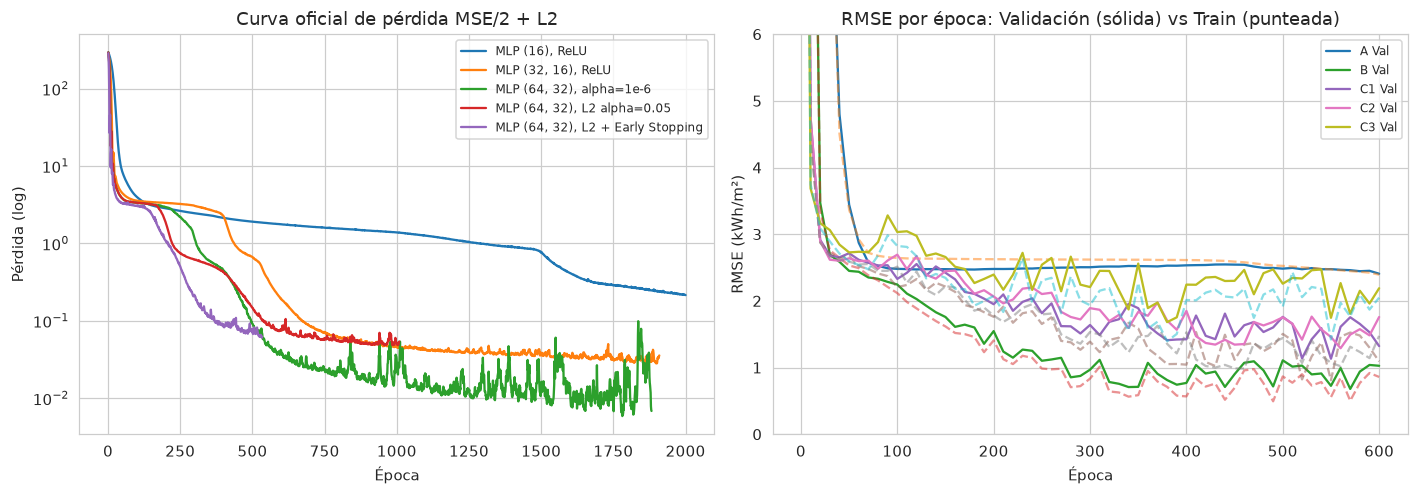

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for exp_id, loss_vals in results["loss_curves_official"].items():
    axes[0].plot(range(1, len(loss_vals) + 1), loss_vals, label=results["mlp_architectures"][exp_id]["name"])
axes[0].set_yscale("log")
axes[0].set_title("Curva oficial de pérdida MSE/2 + L2")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Pérdida (log)")
axes[0].legend(fontsize=8)

for exp_id, lc in results["learning_curves"].items():
    axes[1].plot(lc["epochs"], lc["val_rmse"], label=f"{results['mlp_architectures'][exp_id]['code']} Val")
    axes[1].plot(lc["epochs"], lc["train_rmse"], linestyle="--", alpha=0.5)
axes[1].set_ylim(0, 6.0)
axes[1].set_title("RMSE por época: Validación (sólida) vs Train (punteada)")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("RMSE (kWh/m²)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Evaluación final en Test: Dispersión, Residuos y Subgrupos (Etapa 15)

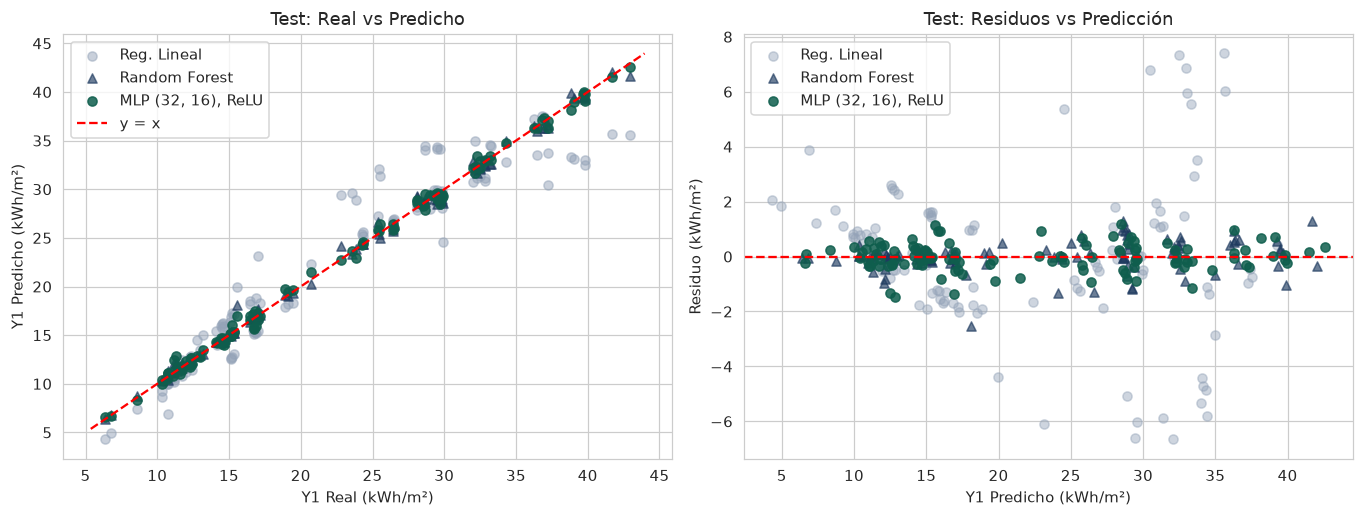

=== MAE Y RMSE POR SUBGRUPOS EN TEST (MEJOR MLP) ===

Subgrupo: Altura total (m)


,subgrupo,valor_raw,n_test,y1_medio,mae,rmse,r2,sesgo_medio
0,3.5 m,3.5,58,13.662,0.3482,0.4724,0.9717,-0.0314
1,7.0 m,7.0,58,30.712,0.4031,0.5204,0.9921,-0.0039



Subgrupo: Orientación


,subgrupo,valor_raw,n_test,y1_medio,mae,rmse,r2,sesgo_medio
0,Norte (2),2.0,26,22.121,0.3405,0.4522,0.9975,0.0033
1,Este (3),3.0,32,26.374,0.4500,0.5457,0.9958,0.0991
2,Sur (4),4.0,32,18.520,0.3306,0.4567,0.9973,-0.0784
3,Oeste (5),5.0,26,21.613,0.3749,0.5237,0.9976,-0.1076



Subgrupo: Área acristalada


,subgrupo,valor_raw,n_test,y1_medio,mae,rmse,r2,sesgo_medio
0,0% (0.00),0.00,8,14.465,0.5022,0.6354,0.9929,-0.1499
1,10% (0.10),0.10,36,19.902,0.3709,0.5082,0.9963,-0.0702
2,25% (0.25),0.25,36,23.427,0.3728,0.4734,0.9977,0.0475
3,40% (0.40),0.40,36,24.948,0.3553,0.4730,0.9976,-0.0010


In [10]:
pred_df = results["predictions_test_df"]
y_true = pred_df["Y1"]
y_mlp = pred_df[f"pred_{best_id}"]
y_lin = pred_df["pred_exp_d1_linear"]
y_rf = pred_df["pred_exp_d2_rf"]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
axes[0].scatter(y_true, y_lin, alpha=0.5, label="Reg. Lineal", color="#94A3B8")
axes[0].scatter(y_true, y_rf, alpha=0.65, marker="^", label="Random Forest", color="#1E3A5F")
axes[0].scatter(y_true, y_mlp, alpha=0.85, label=results["best_mlp"]["name"], color="#0F5E4D")
lims = [y_true.min() - 1, y_true.max() + 1]
axes[0].plot(lims, lims, "r--", label="y = x")
axes[0].set_title("Test: Real vs Predicho")
axes[0].set_xlabel("Y1 Real (kWh/m²)")
axes[0].set_ylabel("Y1 Predicho (kWh/m²)")
axes[0].legend()

axes[1].scatter(y_lin, y_true - y_lin, alpha=0.45, label="Reg. Lineal", color="#94A3B8")
axes[1].scatter(y_rf, y_true - y_rf, alpha=0.65, marker="^", label="Random Forest", color="#1E3A5F")
axes[1].scatter(y_mlp, y_true - y_mlp, alpha=0.85, label=results["best_mlp"]["name"], color="#0F5E4D")
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Test: Residuos vs Predicción")
axes[1].set_xlabel("Y1 Predicho (kWh/m²)")
axes[1].set_ylabel("Residuo (kWh/m²)")
axes[1].legend()
plt.tight_layout()
plt.show()

print("=== MAE Y RMSE POR SUBGRUPOS EN TEST (MEJOR MLP) ===")
for grp_name, rows in results["subgroups_test"]["best_mlp"]["groups"].items():
    print(f"\nSubgrupo: {grp_name}")
    display(pd.DataFrame(rows))

## Etapa 16. Interpretación y demostración con advertencia de extrapolación
Probamos inferencia sobre un diseño válido dentro del dominio y sobre un edificio extremo fuera del rango de entrenamiento para comprobar las alertas automáticas de extrapolación y coherencia geométrica (`X2 ≈ X3 + 2·X4`).

In [11]:
best_pipe = results["pipelines"][best_id]

casos_demo = [
    ("Caso válido (2 plantas, compacto)", {"X1": 0.98, "X2": 514.5, "X3": 294.0, "X4": 110.25, "X5": 7.0, "X6": 2, "X7": 0.25, "X8": 1}),
    ("Caso extremo (extrapolación fuera de rango)", {"X1": 0.50, "X2": 920.0, "X3": 450.0, "X4": 235.0, "X5": 10.5, "X6": 3, "X7": 0.60, "X8": 2}),
]

for titulo, entrada in casos_demo:
    pred = float(best_pipe.predict(pd.DataFrame([entrada]))[0])
    check = check_domain_and_geometry(entrada)
    print(f"--- {titulo} ---")
    print(f"Predicción Y1 ({results['best_mlp']['name']}): {pred:.2f} kWh/m²")
    print(f"¿Dentro del dominio?: {check['is_in_domain']}")
    if check["warnings"]:
        for w in check["warnings"]:
            print("  [ADVERTENCIA]", w)
    print()

--- Caso válido (2 plantas, compacto) ---
Predicción Y1 (MLP (32, 16), ReLU): 29.04 kWh/m²
¿Dentro del dominio?: True

--- Caso extremo (extrapolación fuera de rango) ---
Predicción Y1 (MLP (32, 16), ReLU): 83.13 kWh/m²
¿Dentro del dominio?: False
  [ADVERTENCIA] X1 (Compacidad relativa) = 0.5 está FUERA del rango de entrenamiento [0.62, 0.98]. La predicción es una extrapolación.
  [ADVERTENCIA] X2 (Área superficial) = 920 está FUERA del rango de entrenamiento [514.5, 808.5]. La predicción es una extrapolación.
  [ADVERTENCIA] X3 (Área de paredes) = 450 está FUERA del rango de entrenamiento [245.0, 416.5]. La predicción es una extrapolación.
  [ADVERTENCIA] X4 (Área de techo) = 235 está FUERA del rango de entrenamiento [110.25, 220.5]. La predicción es una extrapolación.
  [ADVERTENCIA] X5 (Altura total) = 10.5 está FUERA del rango de entrenamiento [3.5, 7.0]. La predicción es una extrapolación.
  [ADVERTENCIA] X7 (Área acristalada) = 0.6 está FUERA del rango de entrenamiento [0.0, 0.4